In [1]:
import geopandas as gpd
import osmnx as ox
import pathlib 
NOTEBOOK_PATH = pathlib.Path().resolve()
DATA_DIRECTORY = NOTEBOOK_PATH / "data"
OUTPUT_DIRECTORY = NOTEBOOK_PATH / "docs"
NOTEBOOK_PATH

PosixPath('/home/jovyan/my-work/practical4')

In [2]:
import geopandas
import pandas as pd
# Statistics Finland WFS
LOUNAISTIETO_WFS_BASE_URL = (
    "https://geoserver.lounaistieto.fi/geoserver/service_points/ows"
    "?service=wfs"
    "&version=2.0.0"
    "&request=GetFeature"
    "&srsName=EPSG:3067"
    "&typeName={layer:s}"
)
# Import layer of schools in Finland
kasvatus_ja_koulutuspalvelut = (
    geopandas.read_file(
        LOUNAISTIETO_WFS_BASE_URL.format(layer="kasvatus_ja_koulutuspalvelut")
    )
    .set_crs("EPSG: 3067")
)

koulut = kasvatus_ja_koulutuspalvelut[kasvatus_ja_koulutuspalvelut["palvelukohdetyyppi"]=="Koulut (perusopetus)"]
koulut

,gml_id,kohteen_nimi,palvelukohdetyyppi,palvelut,osoite,aukioloajat,verkkosivu,puhelinnumero,sahkoposti,datalahde,orig_id,geometry
2,kasvatus_ja_koulutuspalvelut.166,Aloittelijoiden painikoulu -palvelun järjestäm...,Koulut (perusopetus),Aloittelijoiden painikoulu,"Oikokuja 6, 21380 AURA",Monday: 17:30:00-18:30:00; Wednesday: 17:30:00...,-,-,-,PTV,a2c5b965-e177-4b99-ae6c-1ad26323b5ca,POINT (258855.969 6731540.5)
3,kasvatus_ja_koulutuspalvelut.499,Wäinö Aaltosen koulun sali,Koulut (perusopetus),"Motionssalar,Bokning av idrottslokaler","Wäinö Aaltosen koulutie 3, 20900 TURKU",-,https://timmi.turku.fi/WebTimmi/login.do?login...,+35822535707,-,PTV,e209c1b4-7c22-4ded-aad2-2c21cf34dded,POINT (237111 6706735)
4,kasvatus_ja_koulutuspalvelut.502,Uittamon koulun sali,Koulut (perusopetus),"Motionssalar,Bokning av idrottslokaler","Jalustinkatu 8, 20880 TURKU",-,https://timmi.turku.fi/WebTimmi/login.do?login...,+35822535707,-,PTV,d0d32aaa-ef01-4f23-a902-cfbbb50963fb,POINT (239162 6707988)
5,kasvatus_ja_koulutuspalvelut.197,Puolalanmäen koulun yläsali,Koulut (perusopetus),"Motionssalar,Bokning av idrottslokaler","Puutarhakatu 5, 20100 TURKU",-,https://timmi.turku.fi/WebTimmi/login.do?login...,-,-,PTV,2f592660-7da0-4869-ac52-ae68a4121417,POINT (239422.984 6711194)
6,kasvatus_ja_koulutuspalvelut.205,Kuusiston koulu,Koulut (perusopetus),"Perusopetuksen iltapäivätoiminta,Perusopetus,O...","Kuusiston koulutie 14, 21620 KUUSISTO",-,https://kaarina.fi/fi/varhaiskasvatus-ja-opetu...,+358503731211,matti.ketola@kaarina.fi,PTV,2a7507e2-ffe6-4080-a9d3-25f4f4b2885a,POINT (246672.219 6703145)
...,...,...,...,...,...,...,...,...,...,...,...,...
357,kasvatus_ja_koulutuspalvelut.732,Pääskyvuoren koulun sali,Koulut (perusopetus),"Motionssalar,Bokning av idrottslokaler","Talvitie 10, 20610 TURKU",-,https://timmi.turku.fi/WebTimmi/login.do?login...,+35822535707,-,PTV,facb2f63-acc0-4854-8fd1-f0fba279b60d,POINT (243495 6709983)
358,kasvatus_ja_koulutuspalvelut.733,Vähä-Heikkilän koulun sali,Koulut (perusopetus),"Motionssalar,Bokning av idrottslokaler","Myllymäentie 42, 20810 TURKU",-,https://timmi.turku.fi/WebTimmi/login.do?login...,+35822535707,-,PTV,faf212bc-c614-4f1d-9a74-602e4f2285f4,POINT (238890 6709130)
359,kasvatus_ja_koulutuspalvelut.734,"Mikaelin koulu, Lyseon yksikkö",Koulut (perusopetus),"Suomenkielinen perusopetus,Oppilaanohjaus,Peru...","Varusmestarintie 19, 20360 TURKU",-,https://blog.edu.turku.fi/mikael/,-,-,PTV,fc8338fb-5998-4c61-9d78-dbbaeec783a6,POINT (240177 6715471)
360,kasvatus_ja_koulutuspalvelut.735,Turun normaalikoulun sali,Koulut (perusopetus),NaN,"Annikanpolku 9, 20610 TURKU",-,https://timmi.turku.fi/WebTimmi/login.do?login...,+35822535707,-,PTV,fde12c1b-b1ce-4e4f-bd3d-62014d84dcce,POINT (244697.125 6710185)


In [3]:
sv = koulut[koulut["palvelut"].str.contains("perusopetus")].copy()
sv

,gml_id,kohteen_nimi,palvelukohdetyyppi,palvelut,osoite,aukioloajat,verkkosivu,puhelinnumero,sahkoposti,datalahde,orig_id,geometry
11,kasvatus_ja_koulutuspalvelut.225,Sirkkala skola,Koulut (perusopetus),Ruotsinkielinen perusopetus,"Sirkkalankatu 20, 20700 TURKU",-,https://blog.edu.turku.fi/sirkkalaskola,-,-,PTV,3d98345e-dc5d-4e12-920b-09bb2e210d4c,POINT (240530 6710393)
12,kasvatus_ja_koulutuspalvelut.235,Naantalin opisto,Koulut (perusopetus),"Taiteen perusopetus,Kansalaisopisto","Opintie 2, 21100 NAANTALI",Monday: 09:00:00-15:00:00; Tuesday: 09:00:00-1...,https://www.naantali.fi/fi/kasvatus-ja-koulutu...,+358447334519; +358447334651; +358445334371,opisto@naantali.fi,PTV,a11450b0-d0bc-4202-8306-fbd53578b783,POINT (227199.203 6714309.5)
13,kasvatus_ja_koulutuspalvelut.252,Topeliuksen koulu,Koulut (perusopetus),"Suomenkielinen perusopetus,Oppilaanohjaus,Peru...","Pakkarinkatu 10, 20100 TURKU",-,https://blog.edu.turku.fi/topelius/,-,-,PTV,43b9734f-471b-4240-9eca-aa8e72b2a76c,POINT (238090 6710020)
15,kasvatus_ja_koulutuspalvelut.254,"Vähä-Heikkilän koulu, Vähä-Heikkilän yksikkö",Koulut (perusopetus),"Perusopetuksen erikoisluokat,Suomenkielinen pe...","Myllymäentie 42, 20810 TURKU",-,https://blog.edu.turku.fi/vahaheikkila/,-,-,PTV,a4151726-be04-47ed-bf2a-c5620c03fc41,POINT (238890 6709130)
17,kasvatus_ja_koulutuspalvelut.507,"Vasaramäen koulu, Lemminkäisenkadun yksikkö",Koulut (perusopetus),"Suomenkielinen perusopetus,Oppilaanohjaus,Peru...","Lemminkäisenkatu 30, 3 krs., 20520 TURKU",-,https://blog.edu.turku.fi/vasaramaki/,+3582330000; +3582330000; +3582330000,-,PTV,53b17404-6c03-417f-bbc6-76c01dab7a9a,POINT (241523 6710521)
...,...,...,...,...,...,...,...,...,...,...,...,...
332,kasvatus_ja_koulutuspalvelut.707,Cygnaeus skola,Koulut (perusopetus),Ruotsinkielinen perusopetus,"Maariankatu 7, 20100 TURKU",-,https://blog.edu.turku.fi/cygnaeus,-,-,PTV,e337afdb-ad64-4b58-8171-7540022d64fa,POINT (239598 6711255)
340,kasvatus_ja_koulutuspalvelut.715,"Hannunniitun koulu, Hannunniitun yksikkö",Koulut (perusopetus),"Suomenkielinen perusopetus,Perusopetuksen aamu...","Virmuntie 3, 20540 TURKU",-,https://blog.edu.turku.fi/hannunniittu/,-,-,PTV,e9407b73-3d2f-4a68-8a76-9752c95cad84,POINT (242972 6711487)
341,kasvatus_ja_koulutuspalvelut.716,"Mikaelin koulu, Urheilupuiston yksikkö",Koulut (perusopetus),"Suomenkielinen perusopetus,Oppilaanohjaus,Peru...","Luolavuorentie 1A, 20520 TURKU",-,https://blog.edu.turku.fi/mikael,-,-,PTV,e945d58b-c2f8-43d7-9cda-92ba7d609498,POINT (239933 6709748)
346,kasvatus_ja_koulutuspalvelut.721,"Hannunniitun koulu, Kohmon yksikkö",Koulut (perusopetus),"Suomenkielinen perusopetus,Perusopetuksen aamu...","Ritavuorenkuja 6, 20540 TURKU",-,http://blog.edu.turku.fi/hannunniittu/,-,-,PTV,edaa585e-896e-4875-85d6-7c921c2528c2,POINT (244204 6711467)


In [4]:
peruskoulut = koulut[koulut["palvelut"].str.contains("Perusopetus")].copy()
peruskoulut
kaikki_koulut = pd.concat([peruskoulut, sv])
kaikki_koulut.sort_values("kohteen_nimi")

,gml_id,kohteen_nimi,palvelukohdetyyppi,palvelut,osoite,aukioloajat,verkkosivu,puhelinnumero,sahkoposti,datalahde,orig_id,geometry
70,kasvatus_ja_koulutuspalvelut.434,Aseman koulu,Koulut (perusopetus),"Perusopetus,Koulukuljetus,Perusopetuksen erity...","Opintie 35, 23100 MYNÄMÄKI",-,https://peda.net/mynamaki/koulut/aseman-koulu,+358445699411,-,PTV,1e62027f-7514-4478-b28b-148a62a34beb,POINT (224427.188 6735076.5)
355,kasvatus_ja_koulutuspalvelut.730,Askaisten koulu,Koulut (perusopetus),"Liikunta ja liikuntapalvelut,Perusopetus,Yksil...","Askaistentie 700, 21240 ASKAINEN",-,https://www.masku.fi/varhaiskasvatus-ja-opetus...,+358400850266,etunimi.sukunimi@masku.fi,PTV,f68c3c14-c24c-48f1-91af-9e99e31df532,POINT (219278.016 6726257)
292,kasvatus_ja_koulutuspalvelut.667,Aunelan koulu,Koulut (perusopetus),"Suomenkielinen perusopetus,Perusopetukseen val...","Opintie 1, 20210 TURKU",-,https://blog.edu.turku.fi/aunela/,-,-,PTV,c65ba803-f474-40e3-991c-d449a521fa77,POINT (236163 6711922)
332,kasvatus_ja_koulutuspalvelut.707,Cygnaeus skola,Koulut (perusopetus),Ruotsinkielinen perusopetus,"Maariankatu 7, 20100 TURKU",-,https://blog.edu.turku.fi/cygnaeus,-,-,PTV,e337afdb-ad64-4b58-8171-7540022d64fa,POINT (239598 6711255)
24,kasvatus_ja_koulutuspalvelut.505,Friisilän koulu,Koulut (perusopetus),"Ruokailu päiväkodeissa, esikoulussa ja kouluis...","Tasalankatu 16, 21200 RAISIO",-,https://www.raisio.fi/fi/koulutus-ja-varhaiska...,+358400719511; +358447971376,etunimi.sukunimi@raisio.fi,PTV,53634572-4347-46a4-842f-58ef1dcadd12,POINT (233854.266 6715093)
...,...,...,...,...,...,...,...,...,...,...,...,...
15,kasvatus_ja_koulutuspalvelut.254,"Vähä-Heikkilän koulu, Vähä-Heikkilän yksikkö",Koulut (perusopetus),"Perusopetuksen erikoisluokat,Suomenkielinen pe...","Myllymäentie 42, 20810 TURKU",-,https://blog.edu.turku.fi/vahaheikkila/,-,-,PTV,a4151726-be04-47ed-bf2a-c5620c03fc41,POINT (238890 6709130)
282,kasvatus_ja_koulutuspalvelut.658,Wäinö Aaltosen koulu,Koulut (perusopetus),"Perusopetuksen erikoisluokat,Suomenkielinen pe...","Wäinö Aaltosen koulutie 3, 20900 TURKU",-,https://blog.edu.turku.fi/wa,-,-,PTV,c22a005e-8b41-4ba4-847b-2b5365ac255c,POINT (237111 6706735)
280,kasvatus_ja_koulutuspalvelut.656,"Yli-Maarian koulu, Moision yksikkö",Koulut (perusopetus),"Suomenkielinen perusopetus,Perusopetuksen aamu...","Moision koulutie 2, 20400 TURKU",-,https://blog.edu.turku.fi/ylimaaria/,-,-,PTV,c187043c-300d-461f-a16e-277f6708b356,POINT (241742 6719641)
300,kasvatus_ja_koulutuspalvelut.675,Yli-Maarian monitoimitalo Ypsilon / Yli-Maaria...,Koulut (perusopetus),"Suomenkielinen esiopetus,Tilapäinen varhaiskas...","Kukkamaariankatu 44, 20400 TURKU",-,-,+358505525060; +3582262063; +358505525060,jenni.rissanen@edu.turku.fi,PTV,cfd2f740-1fbf-4146-b7ab-e0c818ce92ed,POINT (243444 6721010)


In [5]:
turku_koulut = kaikki_koulut[kaikki_koulut["osoite"].str.contains("TURKU")].copy()

In [6]:
# Some rows have same point locaiton but different school yksikkö. 
# group schools by their coordinates and combine their names
turku_koulut["geometry_id"] = turku_koulut.geometry.to_wkt()
schools_combined = turku_koulut.dissolve(
    by="geometry_id",
    aggfunc={
        "kohteen_nimi": lambda x: ", ".join(x),
        "osoite": "first",
        "palvelut": "first"
    },
    as_index=False
).sort_values("kohteen_nimi")

In [7]:
schools_combined

,geometry_id,geometry,kohteen_nimi,osoite,palvelut
1,POINT (236163 6711922),POINT (236163 6711922),Aunelan koulu,"Opintie 1, 20210 TURKU","Suomenkielinen perusopetus,Perusopetukseen val..."
15,POINT (239598 6711255),POINT (239598 6711255),Cygnaeus skola,"Maariankatu 7, 20100 TURKU",Ruotsinkielinen perusopetus
2,POINT (236611 6704848),POINT (236611 6704848),Haarlan koulu,"Meteorikatu 1, 20900 TURKU","Suomenkielinen perusopetus,Perusopetuksen aamu..."
39,POINT (242972 6711487),POINT (242972 6711487),"Hannunniitun koulu, Hannunniitun yksikkö","Virmuntie 3, 20540 TURKU","Suomenkielinen perusopetus,Perusopetuksen aamu..."
42,POINT (244204 6711467),POINT (244204 6711467),"Hannunniitun koulu, Kohmon yksikkö","Ritavuorenkuja 6, 20540 TURKU","Suomenkielinen perusopetus,Perusopetuksen aamu..."
7,POINT (238854 6713900),POINT (238854 6713900),Hepokullan koulu,"Varkkavuorenkatu 42, 20320 TURKU","Perusopetukseen valmistava opetus (VALMO),Suom..."
24,POINT (240438 6707989),POINT (240438 6707989),Ilpoisten koulu,"Lauklähteenkatu 13, 20740 TURKU","Suomenkielinen perusopetus,Perusopetuksen aamu..."
28,POINT (240994 6713973),POINT (240994 6713973),Jäkärlän koulu,"Kärsämäentie 11 2. krs, 20360 TURKU","Suomenkielinen perusopetus,Perusopetuksen aamu..."
33,POINT (241380 6712059),POINT (241380 6712059),Katariinan koulu,"Kirkkotie 31, 20540 TURKU","Suomenkielinen perusopetus,Oppilaanohjaus,Peru..."
31,POINT (241281 6710562),POINT (241281 6710562),"Kiinamyllyn koulu, Datacityn yksikkö","Lemminkäisenkatu 18 C, 20520 TURKU","Suomenkielinen perusopetus,Oppilaanohjaus"


In [8]:
#lukiot
lukiot = kasvatus_ja_koulutuspalvelut[kasvatus_ja_koulutuspalvelut["palvelukohdetyyppi"]=="Lukiot"]
lukiot = lukiot[lukiot["palvelut"].str.contains("lukiokoulutus")]
lukiot.sort_values("kohteen_nimi")
turku_lukiot = lukiot[lukiot["osoite"].str.contains("TURKU")].copy()
turku_lukiot.sort_values("kohteen_nimi")

,gml_id,kohteen_nimi,palvelukohdetyyppi,palvelut,osoite,aukioloajat,verkkosivu,puhelinnumero,sahkoposti,datalahde,orig_id,geometry
392,kasvatus_ja_koulutuspalvelut.769,Katedralskolan i Åbo,Lukiot,"Erityislinjat lukioissa,Ruotsinkielinen lukiok...","Vanha Suurtori 2, 20500 TURKU",-,http://info.edu.turku.fi/katedral/,-,-,PTV,b89fcbfe-c790-4c61-a306-977357281b8b,POINT (240195 6710965)
396,kasvatus_ja_koulutuspalvelut.774,Kerttulin lukio,Lukiot,"Erityislinjat lukioissa,Suomenkielinen lukioko...","Kaarinankatu 3, 20500 TURKU",-,http://www.turku.fi/kerttulin-lukio,-,kerttulin.lukio@edu.turku.fi,PTV,dc10e4fc-9172-4997-9f84-153362153a19,POINT (240636 6710781)
367,kasvatus_ja_koulutuspalvelut.743,Luostarivuoren Lyseon lukio,Lukiot,Suomenkielinen lukiokoulutus,"Luostarinkatu 13, 20700 TURKU",-,http://www.luostarivuorenlyseo.fi/,-,luostarivuoren.lyseon.lukio@edu.turku.fi,PTV,17d2eab0-748d-4e70-bdc7-81b7f95b374e,POINT (239900 6710334)
384,kasvatus_ja_koulutuspalvelut.760,Puolalanmäen lukio,Lukiot,"Erityislinjat lukioissa,Suomenkielinen lukioko...","Aurakatu 11, 20100 TURKU",-,https://blog.edu.turku.fi/pml/,-,-,PTV,824b59d6-407e-42e6-b397-51b4420e9aa8,POINT (239620 6711202)
383,kasvatus_ja_koulutuspalvelut.759,Turun Steiner-koulu,Lukiot,"Suomenkielinen perusopetus,Oppilaanohjaus,Suom...","Kaivokatu 12, 20520 TURKU",-,http://turunsteinerkoulu.fi,+35822734777,kanslia@turunsteinerkoulu.fi,PTV,7fcc0311-2dc2-4d3d-b707-8bf332a72a6f,POINT (240930 6710817)
382,kasvatus_ja_koulutuspalvelut.758,Turun Suomalaisen Yhteiskoulun lukio (TSYK),Lukiot,"Erityislinjat lukioissa,Suomenkielinen lukioko...","Kauppiaskatu 17, 20100 TURKU",-,https://blog.edu.turku.fi/tsyk/,-,-,PTV,7cb782e6-4f58-467a-a84e-5e91bf5a0db4,POINT (239677 6711374)
387,kasvatus_ja_koulutuspalvelut.765,Turun iltalukio,Lukiot,"Iltalukio-opiskelu,Suomenkielinen lukiokoulutus","Eskelinkatu 4, 20100 TURKU",-,http://www.turuniltalukio.fi/,-,-,PTV,a12264b6-44a0-4d03-a111-95c794522533,POINT (239438 6710668)
370,kasvatus_ja_koulutuspalvelut.746,Turun kansainvälinen koulu - Turku Internation...,Lukiot,"Englanninkielinen lukiokoulutus,Suomenkielinen...","Kraatarinkatu 4, 20610 TURKU",-,https://sites.utu.fi/tis/,-,mirjam.rasmus@utu.fi,PTV,28789051-c56e-4a76-b3a1-c9efbdd2dac7,POINT (244655 6710200)
381,kasvatus_ja_koulutuspalvelut.757,Turun klassillinen lukio,Lukiot,"Erityislinjat lukioissa,Suomenkielinen lukioko...","Eskelinkatu 4, 20100 TURKU",-,http://www.turunklassillinenlukio.fi,-,klassillinen.lukio@turku.fi,PTV,773a6869-7846-469e-8586-10a07a2f9196,POINT (239405 6710668)
8,kasvatus_ja_koulutuspalvelut.214,Turun normaalikoulu,Lukiot,"Erityislinjat lukioissa,Suomenkielinen perusop...","Annikanpolku 9, 20610 TURKU",-,https://sites.utu.fi/tnk/,-,-,PTV,1c2adafe-2a52-4f5b-b165-c304a19f2239,POINT (244754 6710232)


In [9]:
schools_combined.to_file(OUTPUT_DIRECTORY / "turku_comprehensive.gpkg")

lukiot.to_file(OUTPUT_DIRECTORY / "lukiot.gpkg")

In [10]:
schools_combined.explore()

<Axes: >

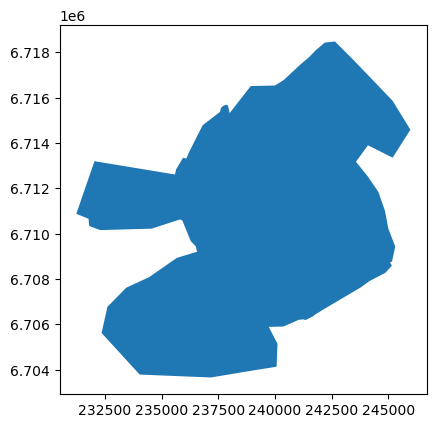

In [11]:
aluerajaus = gpd.read_file(DATA_DIRECTORY/"aluerajaus"/"aluerajaus.shp")
aluerajaus.plot()

In [12]:
turku_lukiot.explore()

In [19]:
ammattikoulut = kasvatus_ja_koulutuspalvelut[kasvatus_ja_koulutuspalvelut["palvelukohdetyyppi"].str.contains("Ammati")].copy()
ammattikoulut_turku = ammattikoulut

,gml_id,kohteen_nimi,palvelukohdetyyppi,palvelut,osoite,aukioloajat,verkkosivu,puhelinnumero,sahkoposti,datalahde,orig_id,geometry
389,kasvatus_ja_koulutuspalvelut.767,"Laitilan kyläkoulu, Kodjalan koulutalo",Ammatillisen koulutuksen instituutit,Avustajapalvelut ja apuvälineet perusopetuksen...,"Vidiläntie 404, 23800 LAITILA",Monday: 08:00:00-15:00:00; Tuesday: 08:00:00-1...,https://sites.google.com/edulaitila.fi/laitila...,+358401984154,kodjalan.koulu@laitila.fi,PTV,55790e35-ffd8-464b-be17-a31e64cabe75,POINT (211174.734 6757900.5)
399,kasvatus_ja_koulutuspalvelut.777,Juhannuskukkulan koulutalo,Ammatillisen koulutuksen instituutit,"Ammatillinen koulutus,Kaksoistutkinto,Opiskeli...","Kukkulakuja 3, 20100 TURKU",Monday: 09:00:00-11:00:00; Monday: 12:00:00-15...,-,-,optsto.jkukkula@edu.turku.fi,PTV,6d36301f-0d6e-4e07-9db1-7536686d1d87,POINT (239202 6711955)
406,kasvatus_ja_koulutuspalvelut.784,Peltolan koulutalon sali,Ammatillisen koulutuksen instituutit,"Motionssalar,Bokning av idrottslokaler","Hamppukatu 2, 20740 TURKU",-,https://timmi.turku.fi/WebTimmi/login.do?login...,+35822535707,-,PTV,08297827-17c2-4bb7-b016-414a0dd242c6,POINT (241240.578 6707715)
407,kasvatus_ja_koulutuspalvelut.785,"Novida, Hämeentien koulutalon opiskeluhuolto, ...",Ammatillisen koulutuksen instituutit,"Opiskeluterveydenhuollon palvelut,Koulukuraatt...","Hämeentie 238, 32200 LOIMAA",Monday: 08:00:00-08:30:00; Tuesday: 08:00:00-0...,https://www.varha.fi/fi/palvelut/terveysasemap...,+358503114737; +358503283314; +358503315646; +...,-,PTV,0e78531b-4724-420c-a39b-4797908292fe,POINT (288157 6750682)
408,kasvatus_ja_koulutuspalvelut.786,Aninkaisten koulutalo,Ammatillisen koulutuksen instituutit,"Ammatillinen koulutus,Kaksoistutkinto,TUVA-kou...","Aninkaistenkatu 7, 20100 TURKU",Monday: 08:30:00-16:00:00; Tuesday: 08:30:00-1...,https://www.turkuai.fi/turun-ammatti-instituut...,-,optsto.aninkainen@edu.turku.fi,PTV,0f6fbd3f-064a-473f-b05a-c7f1e102c708,POINT (240049 6711466)
410,kasvatus_ja_koulutuspalvelut.788,"Novida, Myllykyläntien koulutalon opiskeluhuol...",Ammatillisen koulutuksen instituutit,"Koulukuraattoripalvelut,Koulu- ja opintopsykol...","Myllykyläntie 8, 32201 LOIMAA",Monday: 09:30:00-10:15:00; Tuesday: 09:30:00-1...,https://www.varha.fi/fi/palvelut/terveysasemap...,+358503114670; +358503283314; +358503315646; +...,-,PTV,2504d424-130f-4c4e-9a21-d07760ff783a,POINT (284285 6754103)
411,kasvatus_ja_koulutuspalvelut.789,"Ruiskadun kampus, sosiaali- ja terveysala / Uu...",Ammatillisen koulutuksen instituutit,NaN,"Ruiskatu 8, 20740 TURKU",Monday: 08:00:00-15:00:00; Tuesday: 08:00:00-1...,http://www.turkuai.fi/turun-ammatti-instituutt...,+3582330000,optsto.ruiskatu@edu.turku.fi,PTV,44b18622-c9c7-4322-83be-54260c8c44d0,POINT (241211 6708557)
412,kasvatus_ja_koulutuspalvelut.790,"Laitilan kyläkoulu, Suontaan koulutalo",Ammatillisen koulutuksen instituutit,Avustajapalvelut ja apuvälineet perusopetuksen...,"Vanha Kylätie 12, 23800 LAITILA",Monday: 08:00:00-15:00:00; Tuesday: 08:00:00-1...,https://sites.google.com/edulaitila.fi/laitila...,+358401984154,suontaan.koulu@laitila.fi,PTV,4602ff64-e60c-4356-b5c8-0b9085c279f2,POINT (218965.453 6767529)
413,kasvatus_ja_koulutuspalvelut.791,"Peltolan koulutalon opiskeluhuolto, Turku",Ammatillisen koulutuksen instituutit,"Koulukuraattoripalvelut,Koulu- ja opintopsykol...","Hämeenkatu 10, 20500 TURKU",Monday: 08:00:00-11:00:00; Tuesday: 08:00:00-1...,https://www.varha.fi/fi/palvelut/terveysasemap...,+358449073016; +358449073383; +358449073131; +...,-,PTV,6f4b8b87-3756-4c40-bb25-7fa6b9371093,POINT (240599 6710983)
414,kasvatus_ja_koulutuspalvelut.792,"Laitilan kyläkoulu, Untamalan koulutalo",Ammatillisen koulutuksen instituutit,Avustajapalvelut ja apuvälineet perusopetuksen...,"Untamontie 186, 23800 LAITILA",Monday: 08:00:00-15:00:00; Tuesday: 08:00:00-1...,https://sites.google.com/edulaitila.fi/laitila...,+358401984154,untamalan.koulu@laitila.fi,PTV,716faace-558c-4bbb-a164-092a12763b23,POINT (208589.188 6765404.5)


In [21]:
schools_combined['buffer'] = schools_combined.geometry.buffer(distance=5000)
# For joining based on the buffer, we need to set the buffer as the geometry
schools_combined_buffers = schools_combined.set_geometry("buffer")
schools_combined_buffers.explore()